# Preprocessing with NumPy

In [2]:
import numpy as np

## Checking for Missing Values

In [3]:
lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')

In [4]:
# use the np.isnan() to check for missing values in imported data
# every element in the array is replaced witha boolean value of True or False
np.isnan(lending_co_data_numeric)

array([[False, False, False, False, False, False],
       [False, False, False, False, False, False],
       [False, False, False, False, False, False],
       ...,
       [False, False, False, False, False, False],
       [False, False, False, False, False, False],
       [False, False, False, False, False, False]], shape=(1043, 6))

In [5]:
# it is quicker to do a quality check by summing all the elements in the n-d array
# False = 0 and True = 1
int(np.isnan(lending_co_data_numeric).sum())

# the output of 0 tells us that there are no missing values

0

In [6]:
lending_co_data_numeric_NAN = np.loadtxt("Lending-company-Numeric-NAN.csv", delimiter = ';')

# loadtxt crashes because there are missing values in the value
# so we have to use the genfromtxt function which is able to handle missing values

ValueError: could not convert string '' to float64 at row 11, column 4.

In [ ]:
lending_co_data_numeric_NAN = np.genfromtxt("Lending-company-Numeric-NAN.csv", delimiter = ';')

In [ ]:
np.isnan(lending_co_data_numeric_NAN)

# one missing value can be seen where the boolean result is True

In [ ]:
int(np.isnan(lending_co_data_numeric_NAN).sum())

# summing the whole set of missing values indicates that there are 260 missing values

In [ ]:
# missing values can be replaced with a filler

lending_co_data_numeric_NAN = np.genfromtxt("Lending-company-Numeric-NAN.csv", 
                                            delimiter = ';',
                                            filling_values = 0)

In [ ]:
# using the same method proves that the missing values have now been replaced
int(np.isnan(lending_co_data_numeric_NAN).sum())

In [ ]:
# however a better to handle missing values is not to replace with 0 filler
# but to replace with the highest value in the dataset plus one so we know which missing elements have been replaced
temporary_fill = np.nanmax(lending_co_data_numeric_NAN).round(2) + 1

In [ ]:
float(temporary_fill)

In [ ]:
lending_co_data_numeric_NAN = np.genfromtxt("Lending-company-Numeric-NAN.csv", 
                                            delimiter = ';',
                                            filling_values = temporary_fill)

In [ ]:
# checking to see if there are missing values
int(np.isnan(lending_co_data_numeric_NAN).sum())

## Substituting Missing Values

In [ ]:
lending_co_data_numeric_NAN = np.genfromtxt("Lending-company-Numeric-NAN.csv", delimiter = ';')
lending_co_data_numeric_NAN

In [ ]:
# use the axis = 0 to compute the mean for each column. nanamean mean takes account of missing values by just ignoring them
temporary_mean = np.nanmean(lending_co_data_numeric_NAN, axis = 0).round(2) + 1

In [ ]:
# check the mean for the first column using indexing
float(temporary_mean[0])
# temporary_mean

In [ ]:
temporary_fill = np.nanmax(lending_co_data_numeric_NAN).round(2) + 1

In [ ]:
lending_co_data_numeric_NAN = np.genfromtxt("Lending-company-Numeric-NAN.csv", 
                                            delimiter = ';',
                                            filling_values = temporary_fill)

In [ ]:
# filler value for every missing element in the array
float(temporary_fill)

In [ ]:
# the average value of the first column with missing value replaced by filler
float(np.mean(lending_co_data_numeric_NAN[:,0]).round(2)) # slicing i.e. select every row then comma select the first column and perform the mean

In [ ]:
# mean prior to filling out the missing values
float(temporary_mean[0])

# The filler valie of 64002.0 has made a large difference to the mean in the first column

In [ ]:
# here we are replacing for each element in the first column a condition that where that element equals the temporary fill
# the replacement is with the mean prior to the fillier value
# the idea is that the average of the column with the near value is the same as before the fill value because the averages cancel out
lending_co_data_numeric_NAN[:,0] = np.where(lending_co_data_numeric_NAN[:,0] == temporary_fill,
                                            temporary_mean[0],
                                            lending_co_data_numeric_NAN[:,0])

# This is the most logical way to fill in missing values

Example:

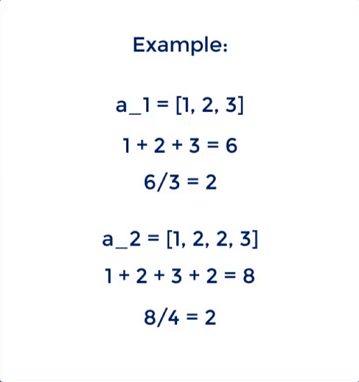

In [ ]:
# this routine iterates through each column (shape[1] gets the total number of columns)
# and if the value equals the temporary fill replace it with the temporary mean i.e. mean before the temporary fill
# else leave value as is
# the i ensures iteratiove of the columns and the columns where the temporary means are also stored
for i in range(lending_co_data_numeric_NAN.shape[1]):
    lending_co_data_numeric_NAN[:,i] = np.where(lending_co_data_numeric_NAN[:,i] == temporary_fill,
                                                temporary_mean[i],
                                                lending_co_data_numeric_NAN[:,i])

In [ ]:
# this example of the modified routine above can be used to replace negative values

for i in range(lending_co_data_numeric_NAN.shape[1]):
    lending_co_data_numeric_NAN[:,i] = np.where(lending_co_data_numeric_NAN[:,i] < 0,
                                                0,
                                                lending_co_data_numeric_NAN[:,i])

## Reshaping

In [ ]:
import numpy as np
lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')

In [ ]:
lending_co_data_numeric

In [ ]:
# Reshaping:
# The act of morphing the shape of an object a certain way
# This is helpful where certain conditions about shapes and sizes need to be met

# Such as not always being possible to store the outputs of a function as part of an existing array (or series)

In [ ]:
# shape of current file
lending_co_data_numeric.shape

# This 1043 rows and 6 columns (a 2-d array)

In [ ]:
# For example we can transform the array i.e. 6 rows and 1043 columns
np.reshape(lending_co_data_numeric, (6,1043))

In [ ]:
# There is a dedicated transpose function in numpy
np.transpose(lending_co_data_numeric)

In [ ]:
# when rehaping the total number of elements must be the shape i.e. the area = length * breadth
np.reshape(lending_co_data_numeric, (3,2086))

In [ ]:
# the shape could be 3 or more dimensions as long as the total number of elements remain the same
np.reshape(lending_co_data_numeric, (2,3,1043))

In [ ]:
# reshape also has an equivelent numpy method of the same name
lending_co_data_numeric.reshape(3,2086)

## Removing Values

In [ ]:
import numpy as np

lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')
lending_co_data_numeric

In [ ]:
# axis is not specified so NumPy flattens the input array into a 1-d array (6*1043 = 6258)
# it then deletes the first element of the array at index 0 (6257)

np.delete(lending_co_data_numeric, 0)

In [ ]:
# the original 2-d array remains unaffected

lending_co_data_numeric.size


In [ ]:
lending_co_data_numeric

In [ ]:
# in order to access the newly modified array it needs to be stored in another variable

lending_co_data_numeric_new = np.delete(lending_co_data_numeric, 0)
lending_co_data_numeric_new

In [ ]:
# in order to delete rows and columns the axis needs to be specified

# deletes the first row specified by the axis
np.delete(lending_co_data_numeric, 0, axis = 0)

In [ ]:
# deletes the first column specified by the axis
np.delete(lending_co_data_numeric, 0, axis = 1)

In [ ]:
# deletes the second column specified by the axis and the index
np.delete(lending_co_data_numeric, 1, axis = 1)

In [ ]:
# multiple columns (and rows) can be deleted by specifying the indexes inside tuples
np.delete(lending_co_data_numeric, (0,2,4), axis = 1)

In [ ]:
# passing multiple columns to be deleted inside lists also works
np.delete(lending_co_data_numeric, [0,2,4], axis = 1)

In [ ]:
# to delete rows and columns at the same time

# the inner delete removes the 1st, 3rd and 5th columns of the dataset
# and the out delete removes the 1st, 3rd and last rows of the dataset
np.delete(np.delete(lending_co_data_numeric, [0,2,4], axis = 1), [0,2,-1], axis = 0)

## Sorting Data

In [ ]:
import numpy as np

lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')
lending_co_data_numeric

In [ ]:
# this sorts the columns (for every row) from low to high because the default is axis = -1 
# negative means traversing the array backwards from the last column to the first column

np.sort(lending_co_data_numeric)

In [ ]:
# sort by rows instead of columns by specifying axis = 0

np.sort(lending_co_data_numeric, axis = 0)

In [ ]:
# This option suppresses scientific notation to get a more readable output

np.set_printoptions(suppress = True)

In [ ]:
# Setting the axis to none sorts all the values in the array in a 1d array from lowest to highest

np.sort(lending_co_data_numeric, axis = None)

In [ ]:
# for comparison with the next output below

np.sort(lending_co_data_numeric)

In [ ]:
# putting a negative sign before the input array turns every element in the ouput array negative

np.sort(-lending_co_data_numeric)

# comparing the above output with the below output makes sense when the array elements are turned negative the order reverses

In [ ]:
# the negative sign at the start of the line reverses the negative values of the output array
# but keeps the way it was sorted previously

-np.sort(-lending_co_data_numeric)

In [ ]:
# the original input array for reference

lending_co_data_numeric

In [ ]:
# only sort values in the third column from low to high

np.sort(lending_co_data_numeric[:,3])

# remember: the sort function returns a sorted version of the original array, rather than sorting it in place

In [ ]:
# to sort the input array in place use the sort method as below

lending_co_data_numeric[:,3].sort()
lending_co_data_numeric

In [ ]:
# to sort the entire array remove the indexing and set the axis = 0 to sort column by column for every row

lending_co_data_numeric.sort(axis = 0)
lending_co_data_numeric

## Argument Functions

### np.argsort()

In [ ]:
import numpy as np

lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')
lending_co_data_numeric

In [ ]:
# the argsort function returns the indices of the array elements that would sort the values
# e.g. the value with index 1 is the smallest i.e. 40

np.argsort(lending_co_data_numeric)

In [ ]:
# the sorting using the argsort function is confirmed by the sort function and returned output array

np.sort(lending_co_data_numeric)

In [ ]:
# using the argsort to sort along columns by specifiying axis = 0

np.argsort(lending_co_data_numeric, axis = 0)

# the index in the upper last column (482) states that this should have the lowest value overall because it has been sorting in ascending order

In [ ]:
# this can be seen using the sort function below

np.sort(lending_co_data_numeric, axis = 0)

In [ ]:
# the argsort function can also be used to sort individual rows or columns by specifying the index

np.argsort(lending_co_data_numeric[:,0], axis = 0)

In [ ]:
# by placing returned index inside the input array all the rows in the first column are sorted except for the other columns

lending_co_data_numeric = lending_co_data_numeric[np.argsort(lending_co_data_numeric[:,0])]
lending_co_data_numeric

# This allows sorting by one column without loosing track of the other columns as they are automatically aligned

### np.argwhere()

In [ ]:
import numpy as np

lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')
lending_co_data_numeric

In [ ]:
# the output from the argwhere functions returns rows (1st column) and columns (2nd column) indexes (i.e. coordinates of the values in the n-d array)
# where the default condition are values different from 0

np.argwhere(lending_co_data_numeric)

In [ ]:
# Hence setting the condition to False returns the indexes where the values are equal to 0

np.argwhere(lending_co_data_numeric == False)

In [ ]:
# confirm that coordinates (116,4) has a value of 0
lending_co_data_numeric[116]

In [ ]:
# any mathematically valid condition can be used to filter the n-d array
# e.g. return all coordinates with a value greater than 1000

np.argwhere(lending_co_data_numeric > 1000)

In [ ]:
# e.g. return all coordinates which are even

np.argwhere(lending_co_data_numeric %2 == 0)

In [ ]:
lending_co_data_numeric_NAN = np.genfromtxt("Lending-company-Numeric-NAN.csv", delimiter = ';')
lending_co_data_numeric_NAN

In [ ]:
# combining argwhere function
# the example below combines the arghwere function with the isnan function to identify the coordinates of nan values

np.argwhere(np.isnan(lending_co_data_numeric_NAN))

In [ ]:
# confirm the the coordinates are returning values equal to nan
# using this technique allows us to discover missing values in out dataset
# note that isnan actually returns True and False boolean values but arghwere sees the True as 0 i.e. it's default where value

lending_co_data_numeric_NAN[11]

# coordinate (11,3) has a nan value

In [ ]:
# in this scenario we want to go through the dataset and substitute each nan value with 0 by looping through all the
# coordinates

for array_index in np.argwhere(np.isnan(lending_co_data_numeric_NAN)): # store in the variable array_index the coordinates for nan values
    #print(array_index)
    lending_co_data_numeric_NAN[array_index[0],array_index[1]] = 0 # reference the 1st and 2nd element (coordinates) and set to 0 in the n-d array

In [ ]:
# we can do a spot check to see if the nan values have been replaced

lending_co_data_numeric_NAN[11]

In [ ]:
# we can do a comprehensive check to see if the nan values have been replaced

int(np.isnan(lending_co_data_numeric_NAN).sum())

# 0 proves that there are no nan values in the dataset

## Shuffling Data

In [8]:
# Shuffling: re-arranging a dataset without a fixed pattern with the end goal being that a random sample would be 
# representative of the entire dataset. Like shuffling a deck of cards.

lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')[:8] # slicing for only the first 8 rows to show shuffling
lending_co_data_numeric

array([[ 2000.,    40.,   365.,  3121.,  4241., 13621.],
       [ 2000.,    40.,   365.,  3061.,  4171., 15041.],
       [ 1000.,    40.,   365.,  2160.,  3280., 15340.],
       [ 2000.,    40.,   365.,  3041.,  4241., 15321.],
       [ 2000.,    50.,   365.,  3470.,  4820., 13720.],
       [ 2000.,    40.,   365.,  3201.,  4141., 14141.],
       [ 2000.,    50.,   365.,  1851.,  3251., 17701.],
       [ 2000.,    40.,   365.,  3971.,  4131., 15351.]])

In [9]:
# the random shuffle function shuffles the n-d array in place
np.random.shuffle(lending_co_data_numeric)

# note: Everytime the random shuffle function is called a new shuffled dataset is generated

In [10]:
lending_co_data_numeric

array([[ 1000.,    40.,   365.,  2160.,  3280., 15340.],
       [ 2000.,    40.,   365.,  3041.,  4241., 15321.],
       [ 2000.,    50.,   365.,  3470.,  4820., 13720.],
       [ 2000.,    40.,   365.,  3971.,  4131., 15351.],
       [ 2000.,    40.,   365.,  3201.,  4141., 14141.],
       [ 2000.,    50.,   365.,  1851.,  3251., 17701.],
       [ 2000.,    40.,   365.,  3121.,  4241., 13621.],
       [ 2000.,    40.,   365.,  3061.,  4171., 15041.]])

In [11]:
# to shuffle the entire dataset just leave out the slicing
lending_co_data_numeric = np.loadtxt("Lending-company-Numeric.csv", delimiter = ',')[:8] # slicing for only the first 8 rows to show shuffling
lending_co_data_numeric

array([[ 2000.,    40.,   365.,  3121.,  4241., 13621.],
       [ 2000.,    40.,   365.,  3061.,  4171., 15041.],
       [ 1000.,    40.,   365.,  2160.,  3280., 15340.],
       [ 2000.,    40.,   365.,  3041.,  4241., 15321.],
       [ 2000.,    50.,   365.,  3470.,  4820., 13720.],
       [ 2000.,    40.,   365.,  3201.,  4141., 14141.],
       [ 2000.,    50.,   365.,  1851.,  3251., 17701.],
       [ 2000.,    40.,   365.,  3971.,  4131., 15351.]])

In [13]:
# this method if importing the shuffle functions makes it easier to call later on rather than using: np.random.shuffle
from numpy.random import shuffle

In [14]:
# shuffling the entire dataset

shuffle(lending_co_data_numeric)
lending_co_data_numeric

array([[ 2000.,    40.,   365.,  3041.,  4241., 15321.],
       [ 2000.,    40.,   365.,  3061.,  4171., 15041.],
       [ 2000.,    40.,   365.,  3971.,  4131., 15351.],
       [ 2000.,    40.,   365.,  3201.,  4141., 14141.],
       [ 1000.,    40.,   365.,  2160.,  3280., 15340.],
       [ 2000.,    50.,   365.,  1851.,  3251., 17701.],
       [ 2000.,    50.,   365.,  3470.,  4820., 13720.],
       [ 2000.,    40.,   365.,  3121.,  4241., 13621.]])

## Casting

## Stripping Data

## Stacking

## Concatenate

## Unique 